# Use a bulk dataset as a reference

Bulk RNA-seq of sorted populations can train viewmastR. `splat_bulk_reference()`
simulates single cells from each bulk profile ("splatting"): each cell gets a library size
drawn from the query's cell sizes, then molecules drawn from the bulk profile. This
tutorial follows the R article
[How to use a bulk dataset as a reference](https://furlan-lab.github.io/viewmastR/articles/BulkReference.html).

| Role | Dataset |
|---|---|
| Bulk reference | sorted haematopoietic populations and AML cells (Corces et al. 2016, GEO GSE74246), as shipped with viewmastR |
| Query 1 | healthy bone marrow atlas (Granja et al. 2019, "Greenleaf reference") |
| Query 2 | AML bone marrow at diagnosis, 16 patients, 15,685 cells (van Galen et al. 2019, GEO GSE116256) |

In [1]:
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import viewmastr as vm
import tutorial_data as td

sc.set_figure_params(dpi=80, frameon=False)
label = td.config().get("greenleaf_label", "celltype")
greenleaf = td.greenleaf_reference()

## Build the bulk object

Columns of the count table are `<donor>-<population>`. As in the R article, the first
reference drops the leukaemic blasts, leukaemia stem cells (LSC) and the rHSC samples.

In [2]:
counts = td.corces_bulk()
meta = pd.DataFrame([c.split("-", 1) for c in counts.columns], columns=["donor", "celltype"], index=counts.columns)
bulk = ad.AnnData(counts.T.to_numpy(dtype=np.float32), obs=meta, var=pd.DataFrame(index=counts.index))
healthy = bulk[~bulk.obs.celltype.str.match("Blast|rHSC|LSC")].copy()
print(healthy.obs.celltype.value_counts().to_string())

celltype
HSC         4
MPP         4
CMP         4
GMP         4
MEP         4
Mono        4
CD4Tcell    4
CD8Tcell    4
NKcell      4
Bcell       4
LMPP        3
CLP         3
Ery         3


## Splat 200 cells per bulk sample

Library sizes come from the Greenleaf cells (`dist="sc-direct"`). The simulated object is
a normal single-cell dataset: normalise, embed and cluster it as usual.

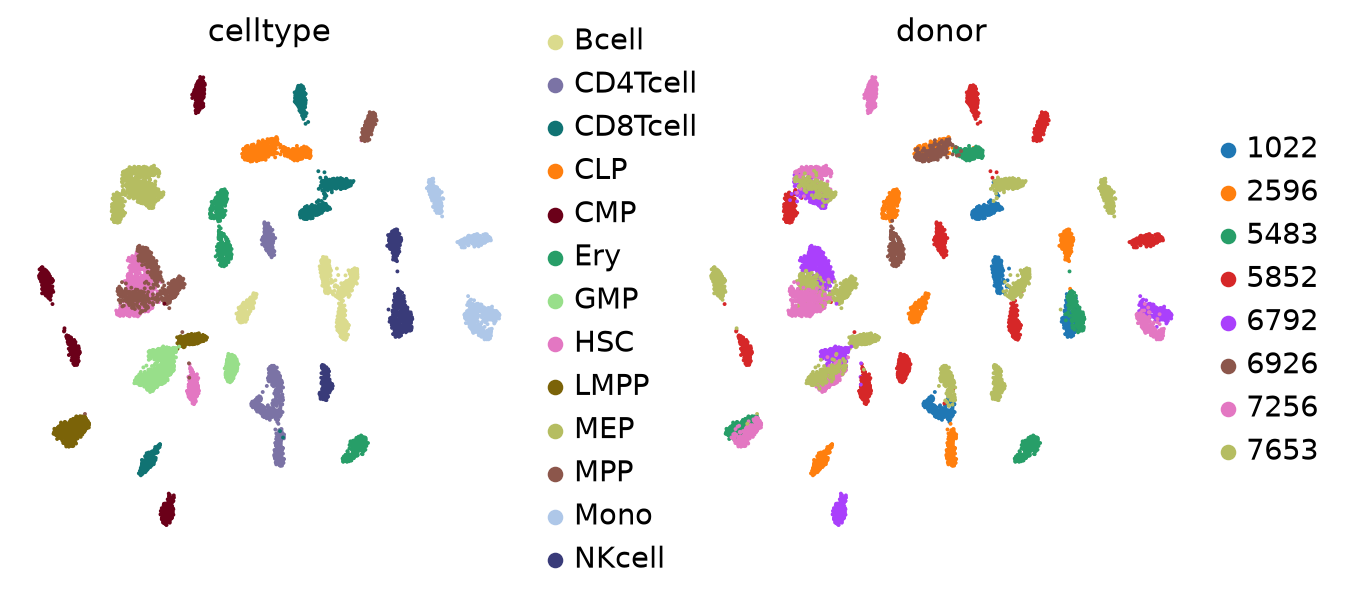

In [3]:
sim = vm.splat_bulk_reference(greenleaf, healthy, N=200)
s = sim.copy()
sc.pp.normalize_total(s, target_sum=1e4)
sc.pp.log1p(s)
sc.pp.highly_variable_genes(s, n_top_genes=1000)
sc.pp.pca(s, n_comps=50, mask_var="highly_variable")
sc.pp.neighbors(s, n_pcs=20)
sc.tl.umap(s, min_dist=0.6)
vm.palette.set_colors(s, "celltype")
sc.pl.umap(s, color=["celltype", "donor"], ncols=2)

## Classify single cells with the bulk reference

Train on the simulated cells and label the Greenleaf atlas. The atlas has its own labels,
so the confusion matrix shows how the bulk populations map onto single-cell types.

viewmastR: 6768 features, 13 classes, 7840 train / 1960 test cells


[epoch 1 | train accuracy 86.339% | validation accuracy 95.561%]


[epoch 2 | train accuracy 98.776% | validation accuracy 97.296%]


[epoch 3 | train accuracy 99.809% | validation accuracy 97.959%]


[epoch 4 | train accuracy 99.923% | validation accuracy 98.367%]


[epoch 5 | train accuracy 99.962% | validation accuracy 98.520%]


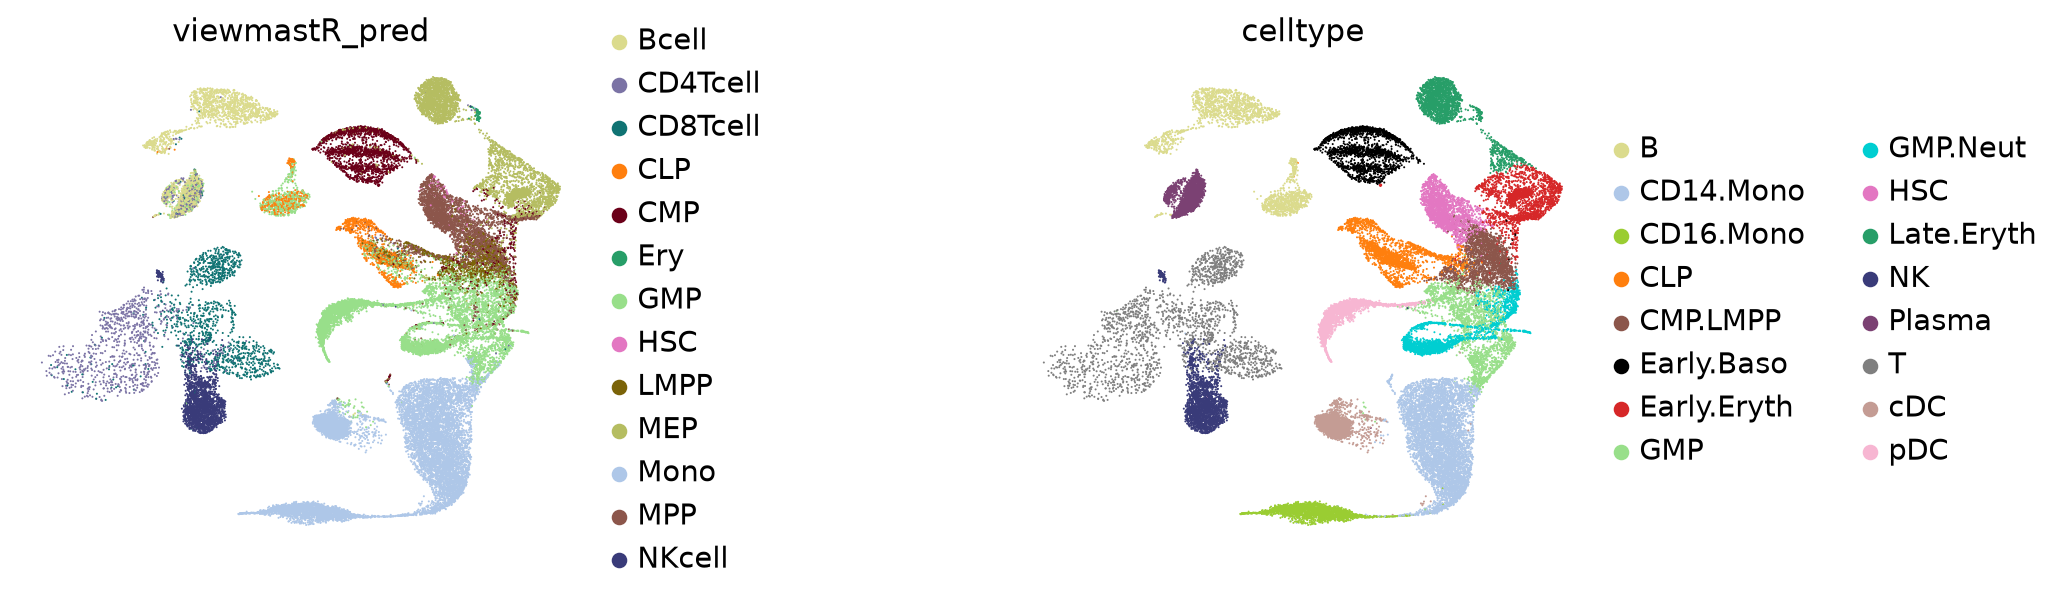

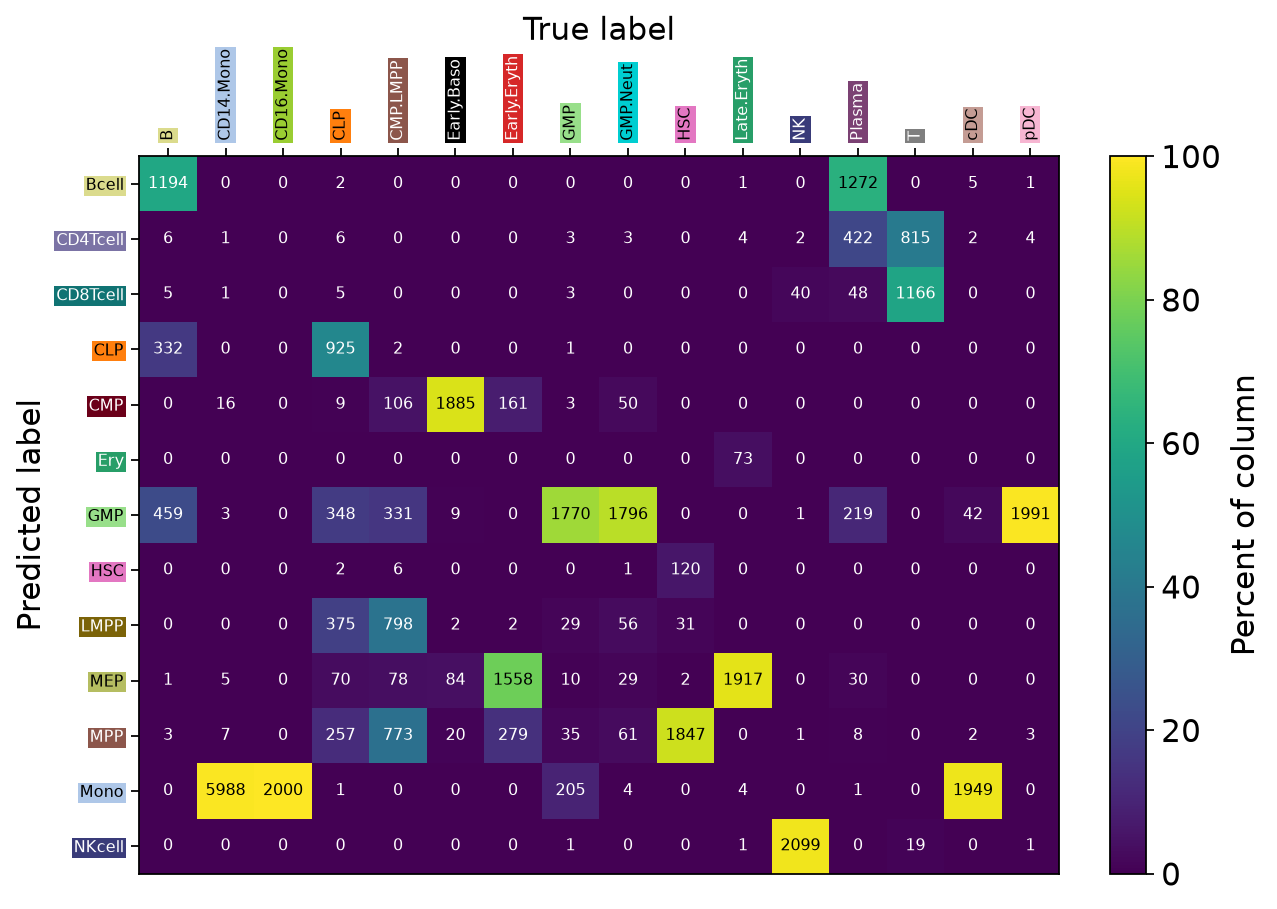

In [4]:
def shared_variable_genes(query, ref):
    for a in (query, ref):
        vm.calculate_feature_dispersion(a)
        vm.select_features(a, top_n=10_000, logmean_ul=-1, logmean_ll=-8)
    vgr = set(vm.get_selected_features(ref))
    return [g for g in vm.get_selected_features(query) if g in vgr]

vg = shared_variable_genes(greenleaf, sim)
vm.viewmastR(greenleaf, sim, "celltype", selected_features=vg)
for key in ("viewmastR_pred", label):
    vm.palette.set_colors(greenleaf, key)
sc.pl.umap(greenleaf, color=["viewmastR_pred", label], ncols=2, wspace=0.6)
vm.confusion_matrix(greenleaf.obs["viewmastR_pred"], greenleaf.obs[label],
                    cols=vm.palette.colors([*greenleaf.obs["viewmastR_pred"], *greenleaf.obs[label]]))
plt.show()

## A leukaemia-aware bulk reference on AML samples

The R article classifies a patient sample with a reference built from leukaemia bulk
profiles. Here the bulk reference keeps every population of the Corces data, including
the blasts and LSC, and 10 cells are splatted per sample. The query is the 16 AML
diagnosis samples of van Galen et al. 2019 (Seq-Well, downloaded from GEO on first use).
Any raw-count h5ad works in its place.

In [5]:
aml = td.vangalen_aml()
sim_all = vm.splat_bulk_reference(aml, bulk, N=10)
vg = shared_variable_genes(aml, sim_all)
_ = vm.viewmastR(aml, sim_all, "celltype", selected_features=vg)

viewmastR: 5393 features, 17 classes, 648 train / 162 test cells


[epoch 1 | train accuracy 20.216% | validation accuracy 20.370%]
[epoch 2 | train accuracy 48.611% | validation accuracy 42.593%]
[epoch 3 | train accuracy 70.370% | validation accuracy 57.407%]
[epoch 4 | train accuracy 86.883% | validation accuracy 64.815%]
[epoch 5 | train accuracy 92.901% | validation accuracy 71.605%]


Embed the AML cells and show the predictions. As in R, labels with fewer than 100 cells
are grouped as "Other".

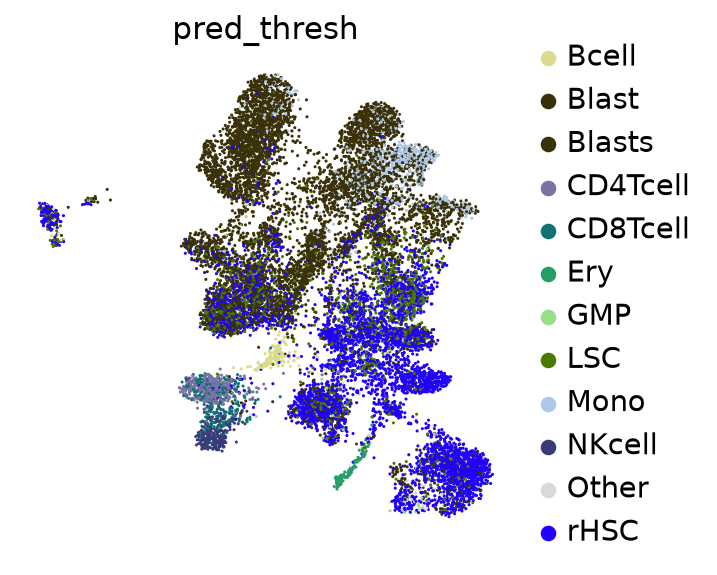

pred_thresh
Blasts      6355
rHSC        5023
LSC         1650
Mono         682
Blast        500
CD4Tcell     392
CD8Tcell     331
NKcell       265
Bcell        173
GMP          112
Ery          108
Other         94


In [6]:
sc.pp.normalize_total(aml, target_sum=1e4)
sc.pp.log1p(aml)
sc.pp.highly_variable_genes(aml, n_top_genes=2000)
sc.pp.pca(aml, n_comps=30, mask_var="highly_variable")
sc.pp.neighbors(aml)
sc.tl.umap(aml)
n = aml.obs["viewmastR_pred"].value_counts()
aml.obs["pred_thresh"] = aml.obs["viewmastR_pred"].astype(str).where(
    aml.obs["viewmastR_pred"].astype(str).isin(n[n >= 100].index), "Other")
vm.palette.set_colors(aml, "pred_thresh")
sc.pl.umap(aml, color="pred_thresh")
print(aml.obs["pred_thresh"].value_counts().to_string())

The authors called each cell malignant or normal from its mutations and expression
(`PredictionRefined`). Cells labelled as blasts or LSC by the leukaemia-aware reference
should be mostly malignant.

In [7]:
pd.crosstab(aml.obs["pred_thresh"], aml.obs["PredictionRefined"])

PredictionRefined,malignant,normal,unclear
pred_thresh,,,
Bcell,2,171,0
Blast,255,42,203
Blasts,5670,506,179
CD4Tcell,0,392,0
CD8Tcell,2,329,0
Ery,0,108,0
GMP,88,19,5
LSC,1268,233,149
Mono,479,109,94


The R article also shows a donor/recipient chimerism panel. It needs per-cell genotype
calls, which these datasets do not carry, so it is not included here.

## Versions

In [8]:
from importlib.metadata import version
for pkg in ("viewmastr", "scanpy", "anndata", "numpy", "scipy"):
    print(f"{pkg:10s} {version(pkg)}")

viewmastr  0.1.0
scanpy     1.12.5
anndata    0.13.4
numpy      2.5.4
scipy      1.18.1
